In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

root = Path("/kaggle/input")

meta_files = list(root.rglob("metadata.npz"))
pred_files = list(root.rglob("test_predictions.npz"))

assert len(meta_files) == 1, "请检查预处理数据输入"
assert len(pred_files) == 1, "请只添加 ResNet 的预测输出"

info = np.load(meta_files[0])
X = np.load(meta_files[0].parent / "X.npy", mmap_mode="r")
predictions = np.load(pred_files[0])

test_prob = predictions["probabilities"]
test_true = predictions["targets"]
thresholds = predictions["thresholds"]
ecg_ids = predictions["ecg_ids"]
classes = info["classes"]

# 确认预测顺序与波形数据对应
np.testing.assert_array_equal(
    ecg_ids,
    info["ecg_ids"][info["test_mask"]],
)

test_pred = (test_prob >= thresholds).astype(int)

summary = pd.DataFrame({
    "类别": classes,
    "正确识别阳性": ((test_true == 1) & (test_pred == 1)).sum(axis=0),
    "漏报": ((test_true == 1) & (test_pred == 0)).sum(axis=0),
    "误报": ((test_true == 0) & (test_pred == 1)).sum(axis=0),
})

display(summary)
print("预测与波形记录编号对齐，加载完成。")

,类别,正确识别阳性,漏报,误报
0,NORM,881,82,209
1,MI,399,151,132
2,STTC,423,98,146
3,CD,345,151,90
4,HYP,160,102,92


预测与波形记录编号对齐，加载完成。


In [3]:
# HYP 漏报：真实标签为 1，预测低于阈值
class_index = list(classes).index("HYP")
scores = test_prob[:, class_index]

fn_indices = np.flatnonzero(
    (test_true[:, class_index] == 1)
    & (test_pred[:, class_index] == 0)
)
fp_indices = np.flatnonzero(
    (test_true[:, class_index] == 0)
    & (test_pred[:, class_index] == 1)
)

# 漏报选分数最低的，误报选分数最高的
selected_fn = fn_indices[np.argsort(scores[fn_indices])[:3]]
selected_fp = fp_indices[np.argsort(-scores[fp_indices])[:3]]

def label_names(vector):
    return ", ".join(classes[vector.astype(bool)])

rows = []

for error_type, indices in [
    ("漏报 FN", selected_fn),
    ("误报 FP", selected_fp),
]:
    for i in indices:
        rows.append({
            "错误类型": error_type,
            "测试集位置": int(i),
            "记录编号": int(ecg_ids[i]),
            "HYP预测分数": float(scores[i]),
            "HYP固定阈值": float(thresholds[class_index]),
            "真实诊断大类": label_names(test_true[i]),
            "预测诊断大类": label_names(test_pred[i]),
        })

cases = pd.DataFrame(rows)
display(cases.round(4))

analysis_dir = Path("/kaggle/working/error_analysis")
analysis_dir.mkdir(exist_ok=True)
cases.to_csv(analysis_dir / "hyp_error_cases.csv", index=False)

,错误类型,测试集位置,记录编号,HYP预测分数,HYP固定阈值,真实诊断大类,预测诊断大类
0,漏报 FN,403,3215,0.0023,0.3261,"STTC, HYP",STTC
1,漏报 FN,194,1556,0.0040,0.3261,"MI, HYP",MI
2,漏报 FN,212,1745,0.0062,0.3261,HYP,NORM
3,误报 FP,2071,20224,0.9508,0.3261,"MI, CD","MI, STTC, HYP"
4,误报 FP,1765,16920,0.8771,0.3261,CD,"MI, STTC, CD, HYP"
5,误报 FP,1022,9167,0.8630,0.3261,STTC,HYP


记录编号： 1745
真实诊断大类： HYP
预测诊断大类： NORM


,类别,预测分数,固定阈值,真实标签
0,NORM,0.9605,0.4718,0
1,MI,0.0081,0.3745,0
2,STTC,0.0212,0.4146,0
3,CD,0.0260,0.4064,0
4,HYP,0.0062,0.3261,1


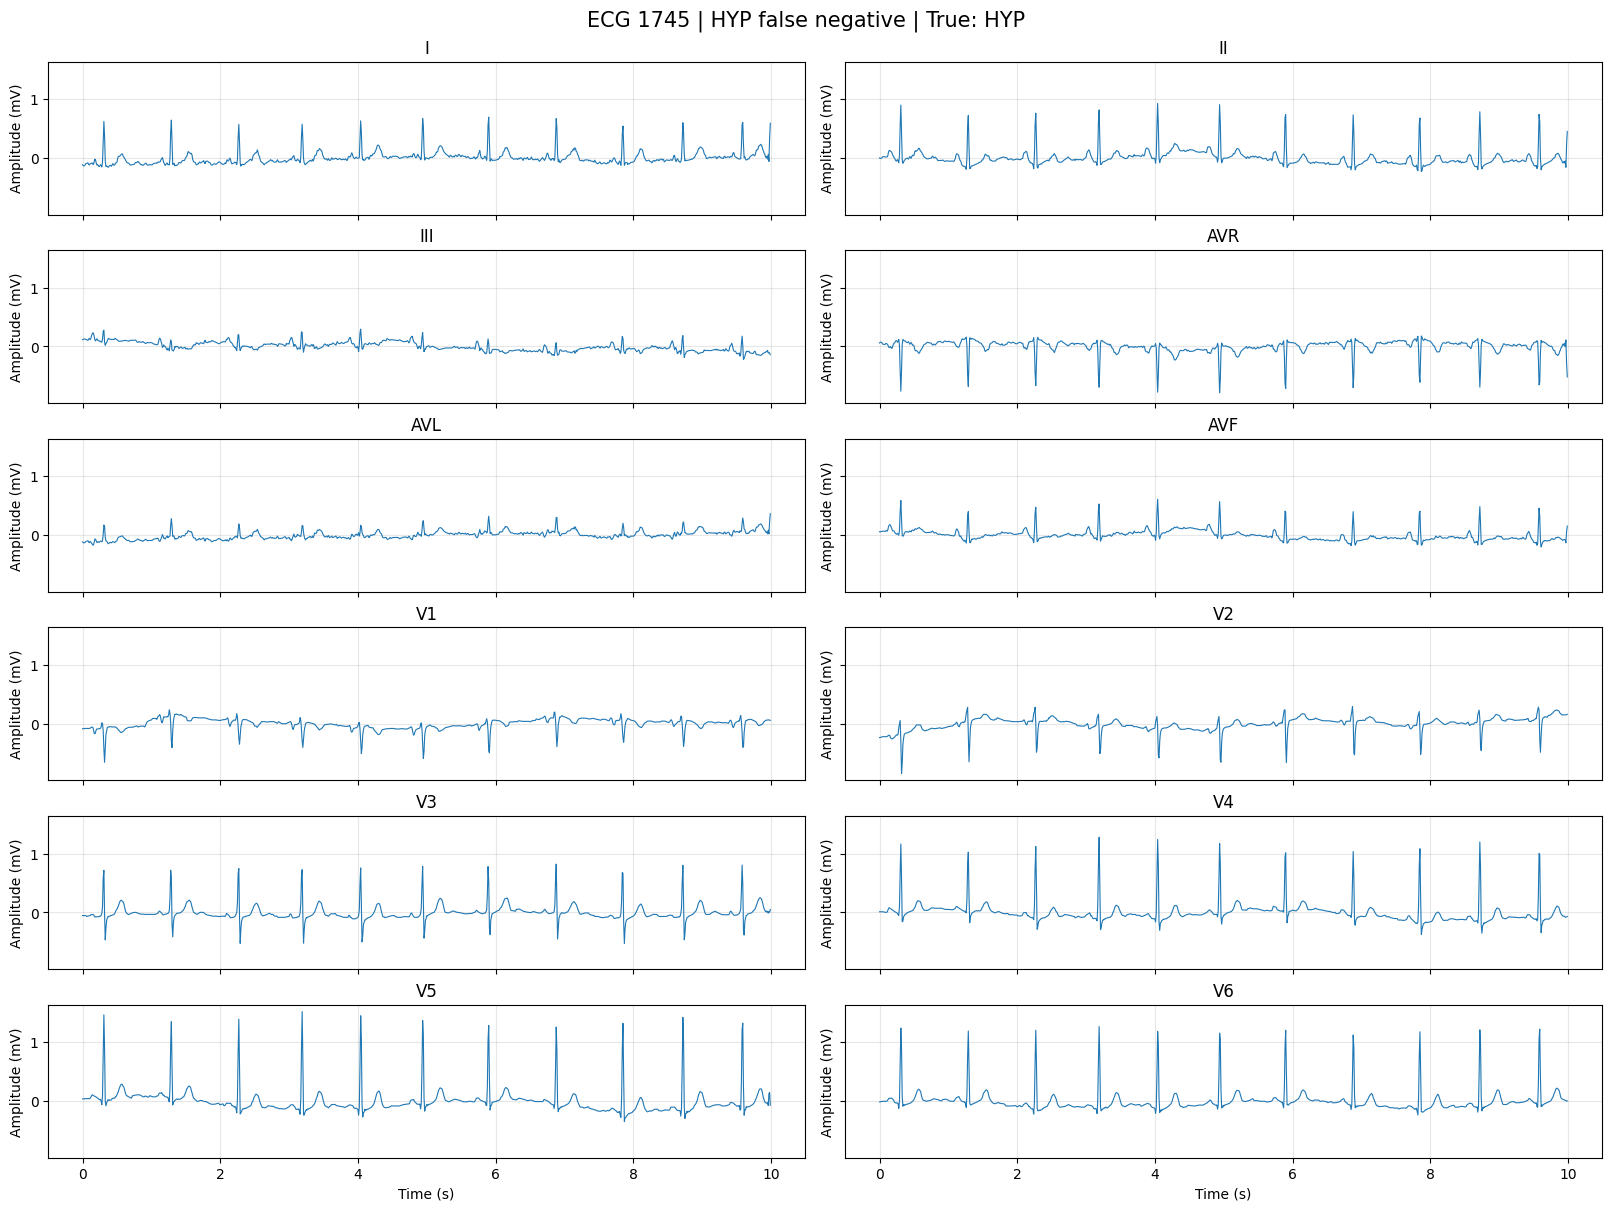

In [4]:
import matplotlib.pyplot as plt

# 选取记录 1745；以后可以替换为案例表中的其他编号
ecg_id = 1745

positions = np.flatnonzero(info["ecg_ids"] == ecg_id)
assert len(positions) == 1, "记录编号未唯一匹配"
position = positions[0]

# 从标准化数据还原到原始电压尺度
waveform = (
    np.asarray(X[position], dtype=np.float32)
    * info["std"][0]
    + info["mean"][0]
)

test_position = np.flatnonzero(ecg_ids == ecg_id)
assert len(test_position) == 1
test_position = test_position[0]

print("记录编号：", ecg_id)
print("真实诊断大类：", label_names(test_true[test_position]))
print("预测诊断大类：", label_names(test_pred[test_position]))

display(pd.DataFrame({
    "类别": classes,
    "预测分数": test_prob[test_position],
    "固定阈值": thresholds,
    "真实标签": test_true[test_position].astype(int),
}).round(4))

time = np.arange(waveform.shape[1]) / 100

fig, axes = plt.subplots(
    6, 2,
    figsize=(16, 12),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for i, ax in enumerate(axes.flat):
    ax.plot(time, waveform[i], linewidth=0.8)
    ax.set_title(str(info["leads"][i]))
    ax.set_ylabel("Amplitude (mV)")
    ax.grid(alpha=0.3)

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")
fig.suptitle(
    f"ECG {ecg_id} | HYP false negative | True: HYP",
    fontsize=15,
)

fig.savefig(
    analysis_dir / f"ecg_{ecg_id}_hyp_fn.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [8]:
import ast

base_url = "https://physionet.org/files/ptb-xl/1.0.3/"

metadata = pd.read_csv(
    base_url + "ptbxl_database.csv",
    index_col="ecg_id",
)
statements = pd.read_csv(
    base_url + "scp_statements.csv",
    index_col=0,
)

sample = metadata.loc[ecg_id]
codes = ast.literal_eval(sample["scp_codes"])

print("记录编号：", ecg_id)
print("原始报告：", sample["report"])
print("原始标注：", codes)

details = statements.loc[
    list(codes),
    ["description", "diagnostic", "diagnostic_class"],
].copy()

details["标注确信度"] = pd.Series(codes)
display(details)

# 保存原始标注，供后续报告引用
details.to_csv(
    analysis_dir / f"ecg_{ecg_id}_annotations.csv"
)

记录编号： 1745
原始报告： sinusrhythmus lagetyp normal vorhofsueberlastung links moeglich normal
原始标注： {'LAO/LAE': 35.0, 'SR': 0.0}


,description,diagnostic,diagnostic_class,标注确信度
LAO/LAE,left atrial overload/enlargement,1.0,HYP,35.0
SR,sinus rhythm,NaN,NaN,0.0


In [9]:
rows = []

for _, case in cases.iterrows():
    case_id = int(case["记录编号"])
    sample = metadata.loc[case_id]
    codes = ast.literal_eval(sample["scp_codes"])

    for code, likelihood in codes.items():
        statement = statements.loc[code]

        if statement["diagnostic"] == 1:
            rows.append({
                "记录编号": case_id,
                "错误类型": case["错误类型"],
                "标注代码": code,
                "含义": statement["description"],
                "诊断大类": statement["diagnostic_class"],
                "标注确信度": likelihood,
            })

case_annotations = pd.DataFrame(rows)
display(case_annotations)

case_annotations.to_csv(
    analysis_dir / "hyp_case_annotations.csv",
    index=False,
)

,记录编号,错误类型,标注代码,含义,诊断大类,标注确信度
0,3215,漏报 FN,LVH,left ventricular hypertrophy,HYP,50.0
1,3215,漏报 FN,NST_,non-specific ST changes,STTC,0.0
2,1556,漏报 FN,IMI,inferior myocardial infarction,MI,50.0
3,1556,漏报 FN,LAO/LAE,left atrial overload/enlargement,HYP,50.0
4,1745,漏报 FN,LAO/LAE,left atrial overload/enlargement,HYP,35.0
5,20224,误报 FP,CLBBB,complete left bundle branch block,CD,100.0
6,20224,误报 FP,ASMI,anteroseptal myocardial infarction,MI,100.0
7,16920,误报 FP,CLBBB,complete left bundle branch block,CD,100.0
8,9167,误报 FP,NDT,non-diagnostic T abnormalities,STTC,100.0


In [10]:
report = """# ResNet：HYP 错误案例分析

## 案例选择
从测试集选择 HYP 分数最低的 3 个漏报、
分数最高的 3 个误报。它们不是随机样本，
不能代表全部错误的分布。

## 观察
1. 漏报记录 3215 的 HYP 标注为 LVH，确信度为 50。
2. 漏报记录 1556、1745 的 HYP 标注为 LAO/LAE，
   确信度分别为 50、35。
3. 误报记录 20224、16920 均含 CLBBB 标注；
   记录 9167 含 NDT 标注。
4. 记录 1745 被模型预测为 NORM，分数为 0.9605，
   HYP 分数为 0.0062；原报告含“可能正常”的表述。

## 解释边界
HYP 大类包含不同细分标注，不能仅用 QRS 电压
解释全部案例。标注确信度不是模型概率。
这些观察不能证明标签错误或模型混淆的原因。
分析用于描述模型局限，不用于继续调整测试集结果。
"""

(analysis_dir / "hyp_error_report.md").write_text(
    report, encoding="utf-8"
)

print("案例分析报告已保存：", analysis_dir / "hyp_error_report.md")

案例分析报告已保存： /kaggle/working/error_analysis/hyp_error_report.md
